# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Mounted at /content/drive
Your working directory is now Google Drive: My Drive > Colab Notebooks


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum.

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):
    """display the board"""

    n = len(board)

    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0):
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap,
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize,
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


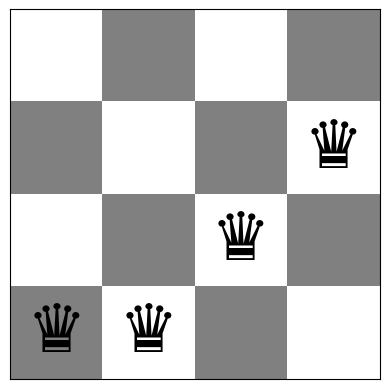

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


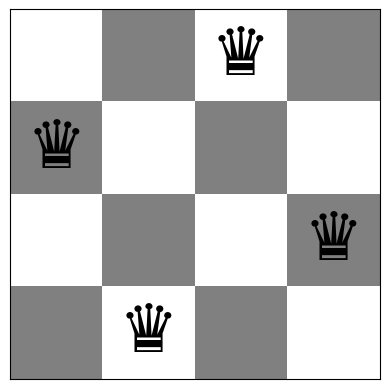

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum.

### Hàm hỗ trợ

Trạng thái là vector `board` (mỗi cột đúng một quân hậu). Một nước đi cục bộ là đổi hàng của một quân hậu trong cột của nó, nên mỗi trạng thái có $n(n-1)$ láng giềng. Biến đếm `eval_count` ghi lại số lần gọi hàm mục tiêu để so sánh chi phí giữa các thuật toán.

In [5]:
import math, time

# Bộ đếm số lần gọi hàm mục tiêu conflicts() để so sánh chi phí tính toán
eval_count = 0
def f(board):
    """Hàm mục tiêu có đếm số lần đánh giá."""
    global eval_count
    eval_count += 1
    return conflicts(board)

def all_moves(n):
    """Mọi nước đi cục bộ: (cột, hàng mới). Có n*(n-1) nước đi."""
    return [(c, r) for c in range(n) for r in range(n)]

def apply_move(board, col, row):
    new = board.copy()
    new[col] = row
    return new


### Cài đặt

Mỗi vòng lặp đánh giá toàn bộ $n(n-1)$ láng giềng, chọn nước giảm xung đột nhiều nhất (hòa thì chọn ngẫu nhiên). Dừng khi không có láng giềng nào **tốt hơn hẳn** hiện tại hoặc khi $f=0$.

In [6]:
def steepest_ascent(board, max_steps=1000):
    """Steepest-ascent HC: xét toàn bộ lân cận, chọn nước giảm xung đột nhiều nhất.
    Dừng khi không có lân cận nào tốt hơn (cực trị cục bộ). Hòa thì chọn ngẫu nhiên."""
    board = np.array(board)
    n = len(board)
    cur = f(board)
    history = [cur]
    for step in range(max_steps):
        best_val, best_moves = cur, []
        for c in range(n):
            for r in range(n):
                if r == board[c]:
                    continue
                val = f(apply_move(board, c, r))
                if val < best_val:
                    best_val, best_moves = val, [(c, r)]
                elif val == best_val and best_moves:
                    best_moves.append((c, r))
        if not best_moves:          # không có bước cải thiện -> dừng
            break
        c, r = best_moves[np.random.randint(len(best_moves))]
        board[c] = r
        cur = best_val
        history.append(cur)
        if cur == 0:
            break
    return board, cur, history


Ban đầu: [7 3 6 5 4 4 0 1] f = 9
Kết thúc: [7 3 7 2 4 6 0 5] f = 1 | số bước: 4 | số lần đánh giá: 281
Board with 1 conflicts.


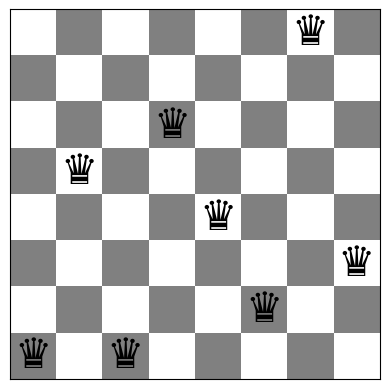

In [7]:
np.random.seed(1234)
eval_count = 0
b0 = random_board(8)
print("Ban đầu:", b0, "f =", conflicts(b0))
b, val, hist = steepest_ascent(b0)
print("Kết thúc:", b, "f =", val, "| số bước:", len(hist) - 1, "| số lần đánh giá:", eval_count)
show_board(b, fontsize=30)

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

### Cài đặt

Giống Task 1 nhưng thay vì chọn nước tốt nhất, thuật toán gom **mọi** nước làm giảm $f$ rồi chọn ngẫu nhiên một nước. Mỗi vòng vẫn tốn $n(n-1)$ lần đánh giá.

In [8]:
def stochastic_hc_all_moves(board, max_steps=1000):
    """Stochastic HC kém hiệu quả: liệt kê MỌI nước cải thiện rồi chọn ngẫu nhiên một nước."""
    board = np.array(board)
    n = len(board)
    cur = f(board)
    history = [cur]
    for step in range(max_steps):
        improving = []
        for c in range(n):
            for r in range(n):
                if r == board[c]:
                    continue
                if f(apply_move(board, c, r)) < cur:
                    improving.append((c, r))
        if not improving:
            break
        c, r = improving[np.random.randint(len(improving))]
        board[c] = r
        cur = conflicts(board)      # giá trị mới (không tính vào bộ đếm, đã biết từ vòng quét)
        history.append(cur)
        if cur == 0:
            break
    return board, cur, history


In [9]:
np.random.seed(1234)
eval_count = 0
b0 = random_board(8)
b, val, hist = stochastic_hc_all_moves(b0)
print("Kết thúc:", b, "f =", val, "| số bước:", len(hist) - 1, "| số lần đánh giá:", eval_count)

Kết thúc: [7 2 0 5 1 4 6 3] f = 0 | số bước: 6 | số lần đánh giá: 337


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way:

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state.
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

### Cài đặt và chọn ngưỡng dừng

Mỗi lần thử chỉ sinh một láng giềng ngẫu nhiên (cột ngẫu nhiên, hàng mới ngẫu nhiên khác hàng hiện tại), nhận ngay nếu giảm $f$. Ngưỡng dừng $x$ là số lần thử liên tiếp không cải thiện. Vì lấy mẫu có hoàn lại từ $N=n(n-1)$ nước, xác suất một nước cụ thể chưa được thử sau $x$ lần xấp xỉ $e^{-x/N}$. Chọn $x = N(\ln N + 2)$ thì số nước bị bỏ sót kỳ vọng chỉ khoảng $e^{-2} \approx 0.14$, tức hầu như đã thử hết láng giềng trước khi kết luận là cực trị cục bộ. Với $n=8$: $N=56$, $x=\lceil 56(\ln 56+2)\rceil=338$.

In [10]:
def stochastic_hc_first_choice(board, patience=None, max_iter=100000):
    """First-choice (Stochastic HC hiệu quả): sinh MỘT lân cận ngẫu nhiên, nhận ngay nếu tốt hơn.
    Dừng khi `patience` lần thử liên tiếp không cải thiện, hoặc hết ngân sách max_iter."""
    board = np.array(board)
    n = len(board)
    N = n * (n - 1)                 # số lân cận
    if patience is None:
        # Lấy mẫu có hoàn lại: xác suất một nước cụ thể chưa được thử sau x lần là (1-1/N)^x ~ e^(-x/N).
        # Chọn x = N*(ln N + 2) => kỳ vọng số nước bỏ sót ~ N*e^(-(ln N + 2)) = e^-2 ~ 0.14.
        patience = math.ceil(N * (math.log(N) + 2))
    cur = f(board)
    history = [cur]
    fails = 0
    for it in range(max_iter):
        c = np.random.randint(n)
        r = np.random.randint(n - 1)
        if r >= board[c]:           # bỏ qua hàng hiện tại: chọn đều trong n-1 hàng còn lại
            r += 1
        val = f(apply_move(board, c, r))
        if val < cur:
            board[c] = r
            cur = val
            fails = 0
        else:
            fails += 1
        history.append(cur)
        if cur == 0 or fails >= patience:
            break
    return board, cur, history


In [11]:
np.random.seed(1234)
eval_count = 0
b0 = random_board(8)
b, val, hist = stochastic_hc_first_choice(b0)
print("Kết thúc:", b, "f =", val, "| số lần thử:", len(hist) - 1, "| số lần đánh giá:", eval_count)

Kết thúc: [1 3 5 7 4 6 0 2] f = 1 | số lần thử: 388 | số lần đánh giá: 389


### So sánh ba biến thể (100 lần chạy mỗi cấu hình, seed cố định)

In [12]:
import pandas as pd

def benchmark(algo, n, runs=100, seed=0):
    """Chạy `runs` lần từ các bàn cờ ngẫu nhiên; trả về số liệu trung bình."""
    global eval_count
    np.random.seed(seed)
    rows = []
    for _ in range(runs):
        b0 = random_board(n)
        eval_count = 0
        t0 = time.perf_counter()
        _, val, hist = algo(b0)
        dt = (time.perf_counter() - t0) * 1000
        rows.append((len(hist) - 1, eval_count, val, dt, val == 0))
    r = np.array(rows, dtype=float)
    return {"Vòng lặp TB": r[:, 0].mean(), "Số lần đánh giá TB": r[:, 1].mean(),
            "f cuối TB": r[:, 2].mean(), "Thời gian TB (ms)": r[:, 3].mean(),
            "Tỉ lệ thành công (%)": 100 * r[:, 4].mean()}

algos = {"Steepest-ascent": steepest_ascent,
         "Stochastic (all moves)": stochastic_hc_all_moves,
         "Stochastic (first-choice)": stochastic_hc_first_choice}
table = []
for n in (4, 8):
    for name, a in algos.items():
        table.append({"Thuật toán": name, "n": n, **benchmark(a, n)})
pd.DataFrame(table).round(2)

,Thuật toán,n,Vòng lặp TB,Số lần đánh giá TB,f cuối TB,Thời gian TB (ms),Tỉ lệ thành công (%)
0,Steepest-ascent,4,1.53,25.60,0.56,0.24,49.0
1,Stochastic (all moves),4,1.75,30.04,0.86,0.28,33.0
2,Stochastic (first-choice),4,50.18,51.18,0.85,0.87,26.0
3,Steepest-ascent,8,3.13,225.56,1.30,3.47,12.0
4,Stochastic (all moves),8,5.30,344.84,1.20,3.24,16.0
5,Stochastic (first-choice),8,333.86,334.86,1.25,4.50,21.0


### Nhận xét (Task 1-3)

- **Chất lượng:** cả ba biến thể đều dễ kẹt ở cực trị cục bộ, tỉ lệ tìm được $f=0$ chỉ khoảng 12-21% với $n=8$ (cao hơn, 26-49%, với $n=4$). Ngoại lệ nhỏ giữa các biến thể chủ yếu do ngẫu nhiên, nên cần nhiều lần chạy và Random Restart (Task 4).
- **Chi phí theo vòng lặp:** Steepest-ascent và Stochastic (all moves) đều đánh giá đủ $n(n-1)$ láng giềng mỗi bước, nên số lần gọi `conflicts()` tăng nhanh theo $n$. Stochastic (all moves) còn phải gom danh sách nước tốt nên chậm hơn Steepest-ascent.
- **First-choice:** mỗi lần thử chỉ tốn một lần đánh giá, nhưng cần rất nhiều lần thử vì phải tự phát hiện cực trị cục bộ bằng ngưỡng `patience`. Ở $n=8$ tổng số lần đánh giá xấp xỉ biến thể all-moves, vì phần lớn chi phí nằm ở các lần thử thất bại cuối cùng. Lợi thế của first-choice rõ hơn khi số láng giềng rất lớn và các bước cải thiện thường gặp.
- **Đánh đổi:** biến thể chọn kỹ (steepest) cho mỗi bước tốt nhưng đắt, biến thể ngẫu nhiên rẻ mỗi bước nhưng cần nhiều bước và ngưỡng dừng; không biến thể nào đảm bảo tìm được nghiệm toàn cục.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

Steepest-ascent | best conflicts = 0 | {'Số lần restart': 2, 'Tổng số bước': 5, 'Tổng số đánh giá': 338}
Board with 0 conflicts.


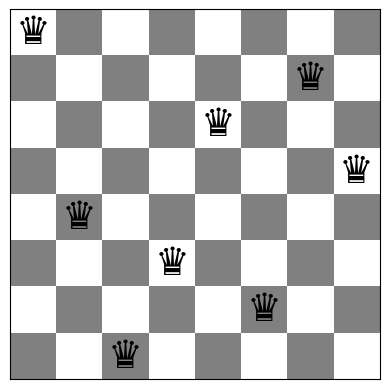

Stochastic (all moves) | best conflicts = 0 | {'Số lần restart': 5, 'Tổng số bước': 27, 'Tổng số đánh giá': 1741}
Board with 0 conflicts.


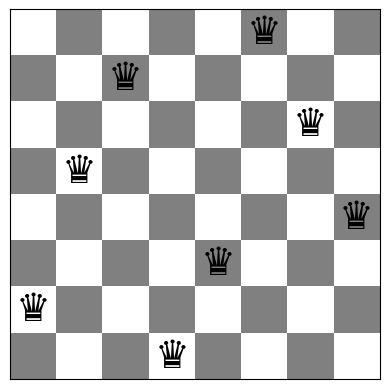

Stochastic (first-choice) | best conflicts = 0 | {'Số lần restart': 1, 'Tổng số bước': 69, 'Tổng số đánh giá': 70}
Board with 0 conflicts.


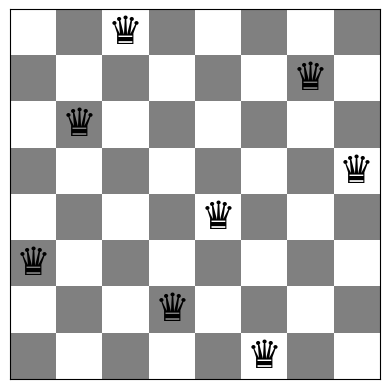

,Thuật toán,Xung đột tốt nhất,Số lần restart,Tổng số bước,Tổng số đánh giá
0,Steepest-ascent,0,2,5,338
1,Stochastic (all moves),0,5,27,1741
2,Stochastic (first-choice),0,1,69,70


In [13]:
def random_restart(algo, n, max_restarts=100):
    """Chạy HC nhiều lần từ bàn cờ ngẫu nhiên; trả nghiệm tốt nhất và thống kê."""
    global eval_count
    best_board, best_val = None, float("inf")
    total_evals, total_steps = 0, 0
    restarts_used = 0
    for restart in range(max_restarts):
        start = random_board(n)
        eval_count = 0
        board, val, history = algo(start)
        total_evals += eval_count
        total_steps += len(history) - 1
        restarts_used += 1
        if val < best_val:
            best_board, best_val = np.array(board).copy(), val
        if best_val == 0:
            break
    return best_board, best_val, {
        "Số lần restart": restarts_used,
        "Tổng số bước": total_steps,
        "Tổng số đánh giá": total_evals
    }

# Thử cả ba biến thể HC, cùng kích thước n=8 và giới hạn 100 lần restart.
np.random.seed(2025)
restart_results = []
for name, algo in [
    ("Steepest-ascent", steepest_ascent),
    ("Stochastic (all moves)", stochastic_hc_all_moves),
    ("Stochastic (first-choice)", stochastic_hc_first_choice)
]:
    board, value, stats = random_restart(algo, n=8, max_restarts=100)
    restart_results.append({"Thuật toán": name, "Xung đột tốt nhất": value, **stats})
    print(name, "| best conflicts =", value, "|", stats)
    if value == 0:
        show_board(board, fontsize=28)
pd.DataFrame(restart_results)

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

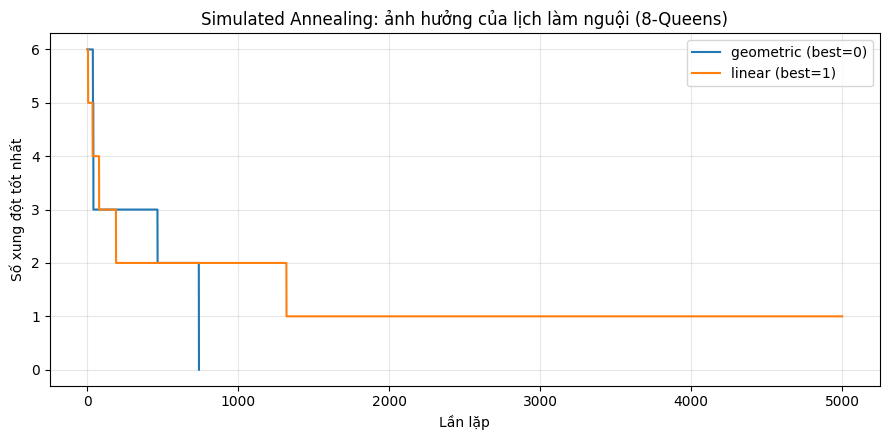

Bàn cờ bắt đầu: [6 6 2 6 4 0 3 3] | xung đột: 6
Lịch geometric: xung đột tốt nhất = 0, số vòng lặp = 739
Board with 0 conflicts.


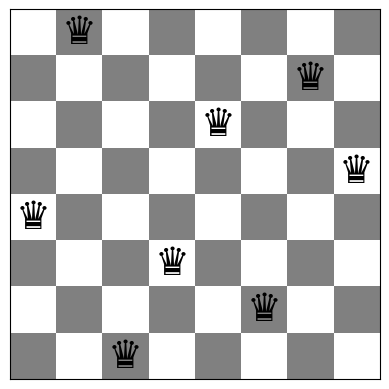

Lịch linear: xung đột tốt nhất = 1, số vòng lặp = 5000


,Lịch,Tham số,Xung đột TB,Tỉ lệ tối ưu (%)
0,geometric,"{'T0': 8.0, 'alpha': 0.995}",0.05,95.0
1,geometric,"{'T0': 20.0, 'alpha': 0.998}",0.10,90.0
2,linear,"{'T0': 8.0, 'cooling_steps': 2500}",0.05,95.0
3,linear,"{'T0': 20.0, 'cooling_steps': 5000}",0.60,40.0


In [14]:
def simulated_annealing(board, schedule="geometric", T0=10.0, Tmin=0.01,
                        alpha=0.995, cooling_steps=5000, max_iter=20000):
    """Simulated annealing; trả bàn cờ tốt nhất, giá trị cuối tốt nhất và lịch sử."""
    board = np.array(board, dtype=int).copy()
    n = len(board)
    current = f(board)
    best_board, best_val = board.copy(), current
    history = [current]
    for t in range(1, max_iter + 1):
        if current == 0:
            break
        col = np.random.randint(n)
        row = np.random.randint(n - 1)
        if row >= board[col]:
            row += 1
        candidate = apply_move(board, col, row)
        candidate_val = f(candidate)
        if schedule == "geometric":
            temperature = max(Tmin, T0 * (alpha ** (t - 1)))
        elif schedule == "linear":
            temperature = max(Tmin, T0 * (1 - (t - 1) / cooling_steps))
        else:
            raise ValueError("schedule must be 'geometric' or 'linear'")
        delta = candidate_val - current
        if delta <= 0 or np.random.random() < np.exp(-delta / max(temperature, 1e-12)):
            board, current = candidate, candidate_val
        if current < best_val:
            best_board, best_val = board.copy(), current
        history.append(best_val)
    return best_board, best_val, history

# Một lượt minh họa cho mỗi lịch làm nguội.
np.random.seed(2025)
start_board = random_board(8)
fig, ax = plt.subplots(figsize=(9, 4.5))
schedule_runs = {}
for schedule in ("geometric", "linear"):
    result_board, result_val, hist = simulated_annealing(
        start_board, schedule=schedule, T0=8.0, alpha=0.997,
        cooling_steps=3000, max_iter=5000
    )
    schedule_runs[schedule] = (result_board, result_val, hist)
    ax.plot(hist, label=f"{schedule} (best={result_val})", linewidth=1.5)
ax.set(title="Simulated Annealing: ảnh hưởng của lịch làm nguội (8-Queens)",
       xlabel="Lần lặp", ylabel="Số xung đột tốt nhất")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print("Bàn cờ bắt đầu:", start_board, "| xung đột:", conflicts(start_board))
for schedule, (b, v, hist) in schedule_runs.items():
    print(f"Lịch {schedule}: xung đột tốt nhất = {v}, số vòng lặp = {len(hist)-1}")
    if v == 0:
        show_board(b, fontsize=28)

# Thử nhanh nhiều tham số để quan sát sự khác biệt; kết quả phụ thuộc seed và tính ngẫu nhiên.
schedule_experiments = []
np.random.seed(2026)
for schedule, params in [
    ("geometric", {"T0": 8.0, "alpha": 0.995}),
    ("geometric", {"T0": 20.0, "alpha": 0.998}),
    ("linear", {"T0": 8.0, "cooling_steps": 2500}),
    ("linear", {"T0": 20.0, "cooling_steps": 5000})
]:
    vals, success = [], []
    for _ in range(20):
        _, val, _ = simulated_annealing(random_board(8), schedule=schedule,
                                        max_iter=5000, **params)
        vals.append(val)
        success.append(val == 0)
    schedule_experiments.append({
        "Lịch": schedule, "Tham số": str(params),
        "Xung đột TB": np.mean(vals), "Tỉ lệ tối ưu (%)": 100*np.mean(success)
    })
pd.DataFrame(schedule_experiments).round(2)

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [15]:
# Task 6 — Comparison: tối thiểu 100 lần chạy cho mỗi thuật toán và kích thước.
# Để công bằng, mỗi lần chạy bắt đầu từ bàn cờ ngẫu nhiên mới; thời gian được đo bằng perf_counter.
def benchmark_algorithms(algorithms, sizes=(4, 8), runs=100, seed=600):
    global eval_count
    rows = []
    for n in sizes:
        for name, algo in algorithms.items():
            np.random.seed(seed + n)
            run_times, final_vals, success_rates, evals = [], [], [], []
            for _ in range(runs):
                start = random_board(n)
                eval_count = 0
                t0 = time.perf_counter()
                _, val, hist = algo(start)
                run_times.append(time.perf_counter() - t0)
                final_vals.append(val)
                success_rates.append(val == 0)
                evals.append(eval_count)
            rows.append({
                "Algorithm": name, "Board size": n,
                "Avg. run time (ms)": 1000*np.mean(run_times),
                "Avg. conflicts": np.mean(final_vals),
                "Optimal runs (%)": 100*np.mean(success_rates),
                "Avg. objective evaluations": np.mean(evals)
            })
    return pd.DataFrame(rows)

algorithms = {
    "Steepest asc. HC": steepest_ascent,
    "Ineff. Stochastic HC": stochastic_hc_all_moves,
    "Efficient Stochastic HC": stochastic_hc_first_choice,
    "Simulated Annealing": simulated_annealing
}
comparison = benchmark_algorithms(algorithms, sizes=(4, 8), runs=100)
display(comparison.round(3))


,Algorithm,Board size,Avg. run time (ms),Avg. conflicts,Optimal runs (%),Avg. objective evaluations
0,Steepest asc. HC,4,0.184,0.64,44.0,25.96
1,Ineff. Stochastic HC,4,0.216,0.75,37.0,32.08
2,Efficient Stochastic HC,4,0.435,0.78,40.0,42.60
3,Simulated Annealing,4,1.396,0.00,100.0,119.65
4,Steepest asc. HC,8,2.212,1.23,17.0,228.92
5,Ineff. Stochastic HC,8,2.910,1.36,13.0,327.48
6,Efficient Stochastic HC,8,4.749,1.24,16.0,358.29
7,Simulated Annealing,8,22.586,0.02,98.0,1422.72


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

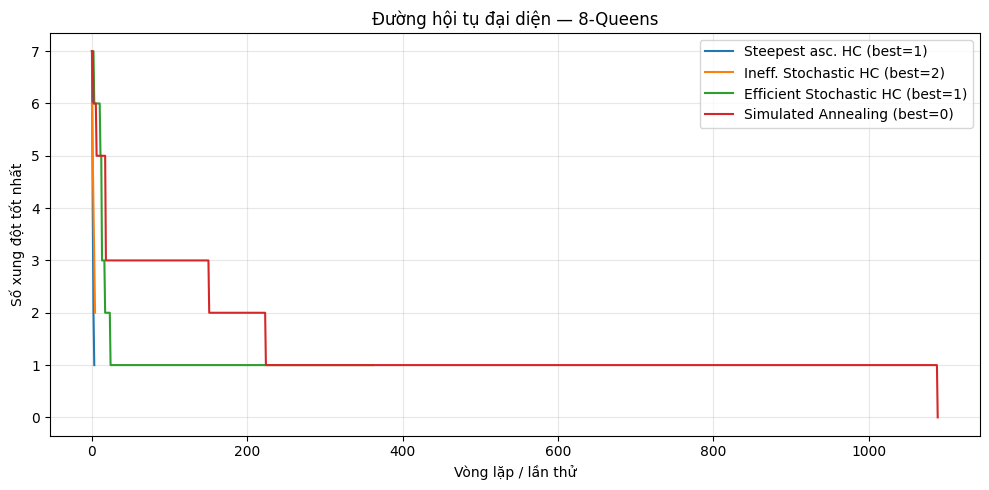

Kết quả đại diện:
- Steepest asc. HC: xung đột tốt nhất = 1; số điểm lịch sử = 4
- Ineff. Stochastic HC: xung đột tốt nhất = 2; số điểm lịch sử = 5
- Efficient Stochastic HC: xung đột tốt nhất = 1; số điểm lịch sử = 363
- Simulated Annealing: xung đột tốt nhất = 0; số điểm lịch sử = 1090

Nhận xét khi đọc đồ thị:
- Steepest-ascent thường giảm nhanh vì khảo sát toàn bộ láng giềng, nhưng dừng ở cực trị cục bộ khi không còn bước tốt hơn.
- Stochastic all-moves cũng chỉ nhận bước cải thiện; đường đi có thể khác do chọn ngẫu nhiên trong các bước tốt.
- First-choice có thể có đoạn nằm ngang dài vì thử nhiều bước không cải thiện trước khi dừng.
- Simulated annealing có thể chấp nhận bước xấu khi nhiệt độ còn cao, giúp thoát bẫy cục bộ; khi nhiệt độ giảm, tiến trình ổn định hơn.
Đây là mô tả xu hướng, không phải bảo đảm cho mọi lần chạy; kết quả thay đổi theo seed và tham số.



In [16]:
# Task 6 — Algorithm convergence: một lần chạy đại diện cho mỗi thuật toán trên 8-Queens.
np.random.seed(808)
representative_histories = {}
for name, algo in algorithms.items():
    _, val, hist = algo(random_board(8))
    representative_histories[name] = (val, hist)

fig, ax = plt.subplots(figsize=(10, 5))
for name, (val, hist) in representative_histories.items():
    ax.plot(hist, label=f"{name} (best={val})", linewidth=1.5)
ax.set(title="Đường hội tụ đại diện — 8-Queens",
       xlabel="Vòng lặp / lần thử", ylabel="Số xung đột tốt nhất")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print("Kết quả đại diện:")
for name, (val, hist) in representative_histories.items():
    print(f"- {name}: xung đột tốt nhất = {val}; số điểm lịch sử = {len(hist)}")

print("""
Nhận xét khi đọc đồ thị:
- Steepest-ascent thường giảm nhanh vì khảo sát toàn bộ láng giềng, nhưng dừng ở cực trị cục bộ khi không còn bước tốt hơn.
- Stochastic all-moves cũng chỉ nhận bước cải thiện; đường đi có thể khác do chọn ngẫu nhiên trong các bước tốt.
- First-choice có thể có đoạn nằm ngang dài vì thử nhiều bước không cải thiện trước khi dừng.
- Simulated annealing có thể chấp nhận bước xấu khi nhiệt độ còn cao, giúp thoát bẫy cục bộ; khi nhiệt độ giảm, tiến trình ổn định hơn.
Đây là mô tả xu hướng, không phải bảo đảm cho mọi lần chạy; kết quả thay đổi theo seed và tham số.
""")


### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

,Algorithm,n,Avg. runtime (s)
0,Steepest asc. HC,4,0.00019
1,Efficient Stochastic HC,4,0.00052
2,Simulated Annealing,4,0.00133
3,Steepest asc. HC,8,0.00203
4,Efficient Stochastic HC,8,0.00688
5,Simulated Annealing,8,0.02981
6,Steepest asc. HC,12,0.00823
7,Efficient Stochastic HC,12,0.01659
8,Simulated Annealing,12,0.04314
9,Steepest asc. HC,16,0.02837


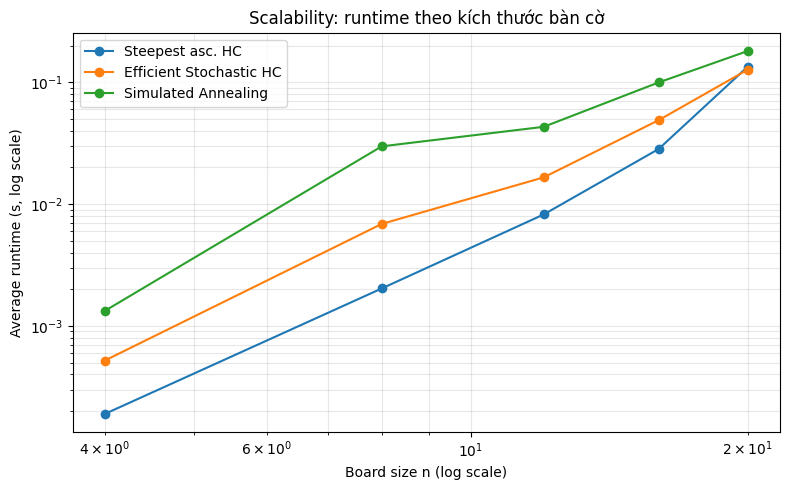

,Algorithm,Empirical exponent k,Approx. trend
0,Steepest asc. HC,3.922,O(n^3.92)
1,Efficient Stochastic HC,3.307,O(n^3.31)
2,Simulated Annealing,2.925,O(n^2.92)



Diễn giải: hệ số k được ước lượng từ một số kích thước nhỏ và các lần chạy ngẫu nhiên,
nên chỉ là xu hướng thực nghiệm, không phải chứng minh độ phức tạp Big-O lý thuyết.
Steepest-ascent đánh giá O(n^2) láng giềng ở mỗi bước; mỗi lần đánh giá conflicts tốn O(n),
nên chi phí mỗi bước xấp xỉ O(n^3). First-choice và simulated annealing đánh giá một láng giềng
mỗi vòng (mỗi lần conflicts tốn O(n)), nhưng tổng số vòng lặp phụ thuộc ngẫu nhiên và lịch dừng.



In [17]:
# Task 6 — Scalability. Đo thời gian trên n=4, 8, 12, 16, 20.
# Dùng ít lượt hơn ở phần này vì đây là khảo sát xu hướng; bảng so sánh chính phía trên vẫn dùng 100 lượt.
def scalability_run(algo, n, runs=5):
    times = []
    for _ in range(runs):
        start = random_board(n)
        t0 = time.perf_counter()
        algo(start)
        times.append(time.perf_counter() - t0)
    return float(np.mean(times))

scalability_algorithms = {
    "Steepest asc. HC": steepest_ascent,
    "Efficient Stochastic HC": stochastic_hc_first_choice,
    "Simulated Annealing": simulated_annealing
}
sizes = [4, 8, 12, 16, 20]
scalability_rows = []
for n in sizes:
    for name, algo in scalability_algorithms.items():
        # Chạy 5 lần cho mỗi điểm; thời gian có thể biến động do thuật toán ngẫu nhiên.
        avg_seconds = scalability_run(algo, n, runs=5)
        scalability_rows.append({"Algorithm": name, "n": n, "Avg. runtime (s)": avg_seconds})
scalability = pd.DataFrame(scalability_rows)
display(scalability.round(5))

fig, ax = plt.subplots(figsize=(8, 5))
for name in scalability_algorithms:
    part = scalability[scalability["Algorithm"] == name]
    ax.loglog(part["n"], part["Avg. runtime (s)"], marker="o", label=name)
ax.set(title="Scalability: runtime theo kích thước bàn cờ",
       xlabel="Board size n (log scale)", ylabel="Average runtime (s, log scale)")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Ước lượng số mũ thực nghiệm tỉ lệ runtime ~ n^k bằng hồi quy tuyến tính trên log-log.
complexity_rows = []
for name in scalability_algorithms:
    part = scalability[scalability["Algorithm"] == name]
    x = np.log(part["n"].to_numpy(dtype=float))
    y = np.log(np.maximum(part["Avg. runtime (s)"].to_numpy(dtype=float), 1e-9))
    slope = np.polyfit(x, y, 1)[0]
    complexity_rows.append({"Algorithm": name, "Empirical exponent k": slope,
                            "Approx. trend": f"O(n^{slope:.2f})"})
display(pd.DataFrame(complexity_rows).round(3))

print("""
Diễn giải: hệ số k được ước lượng từ một số kích thước nhỏ và các lần chạy ngẫu nhiên,
nên chỉ là xu hướng thực nghiệm, không phải chứng minh độ phức tạp Big-O lý thuyết.
Steepest-ascent đánh giá O(n^2) láng giềng ở mỗi bước; mỗi lần đánh giá conflicts tốn O(n),
nên chi phí mỗi bước xấp xỉ O(n^3). First-choice và simulated annealing đánh giá một láng giềng
mỗi vòng (mỗi lần conflicts tốn O(n)), nhưng tổng số vòng lặp phụ thuộc ngẫu nhiên và lịch dừng.
""")


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [18]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Implement a Genetic Algorithm for the n-Queens problem

In [19]:
# Code and description go here

In [37]:
  !git config --global user.email "genjikhang365@gmail.com"
  !git config --global user.name "WhaleeYHN"

In [40]:
!git add n_queens.ipynb
!git diff --cached --stat
!git commit -m "Implement N-Queens tasks 4-6"
!git push -u origin feature/nqueens-task-4-6

On branch feature/nqueens-task-4-6
Your branch is up to date with 'origin/feature/nqueens-task-4-6'.

nothing to commit, working tree clean
fatal: could not read Username for 'https://github.com': No such device or address
